In [1]:
#Cell 1：安装、初始化及连接 Drive
!pip -q install vmas

import vmas
import torch
import numpy as np
import matplotlib.pyplot as plt
import json
import time
import importlib.metadata

from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/MAWM_Research")
E4_DIR = ROOT / "E4"
CEM_DIR = E4_DIR / "CEM_baselines"
CEM_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

SEED = 42
MAX_STEPS = 200
GOAL_TOL = 0.12
SAFE_DISTANCE = 0.30

STARTS = np.array([
    [-0.8, -0.8],
    [-0.8,  0.8]
], dtype=np.float32)

GOALS = np.array([
    [0.8,  0.8],
    [0.8, -0.8]
], dtype=np.float32)

CEM_CONFIG = {
    "horizon": 8,
    "population": 64,
    "iterations": 3,
    "elite_fraction": 0.125,
    "max_steps": 200,
    "goal_weight": 5.0,
    "action_weight": 0.01,
    "safety_weight": 100.0,
    "seed": SEED
}

torch.manual_seed(SEED)
np.random.seed(SEED)

print("Device:", DEVICE)
print("VMAS:", importlib.metadata.version("vmas"))
print("E4-B initialized")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Mounted at /content/drive
Device: cuda
VMAS: 1.5.2
E4-B initialized


In [2]:
#Cell 2：创建固定 S1 场景
def create_scenario(num_envs=1):
    env = vmas.make_env(
        scenario="navigation",
        num_envs=num_envs,
        n_agents=2,
        device=DEVICE,
        continuous_actions=True,
        max_steps=MAX_STEPS,
        seed=SEED
    )

    env.reset()

    with torch.no_grad():
        for i, agent in enumerate(env.agents):
            p = torch.as_tensor(
                STARTS[i], device=DEVICE
            ).reshape(1, 2).expand(num_envs, 2).clone()

            g = torch.as_tensor(
                GOALS[i], device=DEVICE
            ).reshape(1, 2).expand(num_envs, 2).clone()

            agent.set_pos(p, batch_index=None)
            agent.set_vel(torch.zeros_like(p), batch_index=None)
            agent.goal.set_pos(g, batch_index=None)

            if hasattr(agent, "pos_shaping"):
                agent.pos_shaping[:] = (
                    torch.linalg.vector_norm(p-g, dim=-1)
                    * env.scenario.pos_shaping_factor
                )

    return env


def set_cem_state(sim, positions, velocities):
    """
    将全部候选仿真环境恢复到相同状态。
    """
    B = sim.num_envs
    sim.reset()

    with torch.no_grad():
        for i, agent in enumerate(sim.agents):
            p = torch.as_tensor(
                positions[i], device=DEVICE,
                dtype=torch.float32
            ).reshape(1, 2).expand(B, 2).clone()

            v = torch.as_tensor(
                velocities[i], device=DEVICE,
                dtype=torch.float32
            ).reshape(1, 2).expand(B, 2).clone()

            g = torch.as_tensor(
                GOALS[i], device=DEVICE,
                dtype=torch.float32
            ).reshape(1, 2).expand(B, 2).clone()

            agent.set_pos(p, batch_index=None)
            agent.set_vel(v, batch_index=None)
            agent.goal.set_pos(g, batch_index=None)

            if hasattr(agent, "pos_shaping"):
                agent.pos_shaping[:] = (
                    torch.linalg.vector_norm(p-g, dim=-1)
                    * sim.scenario.pos_shaping_factor
                )


# ===== Cell 2: Environment Verification =====

real_env = create_scenario(1)
sim_env = create_scenario(CEM_CONFIG["population"])

print("Real environments:", real_env.num_envs)
print("Candidate environments:", sim_env.num_envs)

for i, agent in enumerate(sim_env.agents):
    print(f"\nAgent {i}")
    print("Position shape:", agent.state.pos.shape)
    print("Velocity shape:", agent.state.vel.shape)
    print("Action dimension:", agent.action_size)
    print("Action range:", agent.u_range)

print("\nCell 2 verification successful!")

Real environments: 1
Candidate environments: 64

Agent 0
Position shape: torch.Size([64, 2])
Velocity shape: torch.Size([64, 2])
Action dimension: 2
Action range: 1.0

Agent 1
Position shape: torch.Size([64, 2])
Velocity shape: torch.Size([64, 2])
Action dimension: 2
Action range: 1.0

Cell 2 verification successful!


In [3]:
#Cell 3：实现 Centralized CEM
def centralized_cem(
    sim, positions, velocities, config,
    with_safety=True, seed=42
):
    device = sim.device
    B = config["population"]
    H = config["horizon"]

    assert sim.num_envs == B

    generator = torch.Generator(device=device)
    generator.manual_seed(seed)

    limits = torch.tensor(
        [float(a.u_range) for a in sim.agents],
        device=device
    ).reshape(1, 1, 2, 1)

    mean = torch.zeros(H, 2, 2, device=device)
    std = torch.full((H, 2, 2), 0.6, device=device)

    n_elite = max(
        2, int(B * config["elite_fraction"])
    )

    goals = torch.as_tensor(
        GOALS, device=device, dtype=torch.float32
    )

    best_cost = float("inf")
    best_action = None
    initial_cost = None

    for iteration in range(config["iterations"]):

        noise = torch.randn(
            B, H, 2, 2,
            device=device, generator=generator
        )

        candidates = (
            mean.unsqueeze(0) + std.unsqueeze(0)*noise
        )

        candidates = torch.maximum(
            torch.minimum(candidates, limits), -limits
        )

        # 所有候选从同一物理状态出发
        set_cem_state(sim, positions, velocities)

        with torch.no_grad():
            safety_cost = torch.zeros(B, device=device)

            for h in range(H):
                actions = [
                    candidates[:, h, i, :]
                    for i in range(2)
                ]

                sim.step(actions)

                p0 = sim.agents[0].state.pos
                p1 = sim.agents[1].state.pos

                d = torch.linalg.vector_norm(
                    p0 - p1, dim=-1
                )

                safety_cost += (
                    torch.relu(SAFE_DISTANCE-d)**2
                )

            final_positions = torch.stack(
                [a.state.pos for a in sim.agents],
                dim=1
            )

            goal_cost = torch.linalg.vector_norm(
                final_positions-goals.unsqueeze(0),
                dim=-1
            ).sum(dim=1)

            action_cost = candidates.pow(2).mean(
                dim=(1, 2, 3)
            )

            costs = (
                config["goal_weight"]*goal_cost
                + config["action_weight"]*action_cost
            )

            if with_safety:
                costs = (
                    costs
                    + config["safety_weight"]*safety_cost
                )

        if iteration == 0:
            initial_cost = float(costs.min().item())

        indices = torch.topk(
            costs, n_elite, largest=False
        ).indices

        elites = candidates[indices]
        mean = elites.mean(dim=0)
        std = elites.std(dim=0, unbiased=False).clamp(min=0.05)

        idx = torch.argmin(costs)
        current_cost = float(costs[idx].item())

        if current_cost < best_cost:
            best_cost = current_cost
            best_action = candidates[idx, 0].clone()

    return best_action, {
        "best_cost": best_cost,
        "initial_best_cost": initial_cost
    }

In [4]:
#Cell 4：单步测试
#先测试是否能够输出两个 Agent 的联合动作，避免马上运行完整实验。
positions = np.stack([
    a.state.pos[0].detach().cpu().numpy()
    for a in real_env.agents
])

velocities = np.stack([
    a.state.vel[0].detach().cpu().numpy()
    for a in real_env.agents
])

joint_action, info = centralized_cem(
    sim_env,
    positions,
    velocities,
    CEM_CONFIG,
    with_safety=True,
    seed=42
)

print("Joint action shape:", joint_action.shape)
print("Joint action:", joint_action)
print("Planning information:", info)

Joint action shape: torch.Size([2, 2])
Joint action: tensor([[ 0.4946,  0.6152],
        [ 0.5867, -0.7140]], device='cuda:0')
Planning information: {'best_cost': 21.403921127319336, 'initial_best_cost': 22.06525993347168}


In [5]:
#Cell 5：运行完整闭环实验
#这次代码同时支持带安全约束和不带安全约束的两种模式。
def run_centralized_experiment(with_safety=True, seed=42):
    env = create_scenario(1)
    sim = create_scenario(CEM_CONFIG["population"])

    trajectories = [[], []]
    separations = []
    planning_times = []

    termination = "max_steps"

    def record():
        ps = [
            a.state.pos[0].detach().cpu().numpy().copy()
            for a in env.agents
        ]

        for i in range(2):
            trajectories[i].append(ps[i])

        separations.append(float(
            np.linalg.norm(ps[0]-ps[1])
        ))

    record()

    for step in range(CEM_CONFIG["max_steps"]):
        positions = np.stack([
            a.state.pos[0].detach().cpu().numpy()
            for a in env.agents
        ])

        velocities = np.stack([
            a.state.vel[0].detach().cpu().numpy()
            for a in env.agents
        ])

        distances = np.linalg.norm(
            positions-GOALS, axis=1
        )

        if np.all(distances < GOAL_TOL):
            termination = "joint_success"
            break

        if DEVICE == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()

        action, info = centralized_cem(
            sim, positions, velocities,
            CEM_CONFIG,
            with_safety=with_safety,
            seed=seed+step
        )

        if DEVICE == "cuda":
            torch.cuda.synchronize()

        planning_times.append(
            (time.perf_counter()-t0)*1000
        )

        actions = [
            action[i].unsqueeze(0)
            for i in range(2)
        ]

        _, _, dones, _ = env.step(actions)
        record()

        if bool(torch.all(dones)):
            termination = "environment_done"
            break

    trajectories = [np.asarray(t) for t in trajectories]
    separations = np.asarray(separations)

    final_positions = np.stack([
        a.state.pos[0].detach().cpu().numpy()
        for a in env.agents
    ])

    final_distances = np.linalg.norm(
        final_positions-GOALS, axis=1
    )

    success = bool(np.all(final_distances < GOAL_TOL))
    if success:
        termination = "joint_success"

    collision_threshold = sum(
        float(a.shape.radius) for a in env.agents
    )

    result = {
        "experiment": "E4-B",
        "method": "Centralized_CEM",
        "with_safety": with_safety,
        "steps": len(separations)-1,
        "joint_success": success,
        "termination": termination,
        "minimum_separation": float(separations.min()),
        "loss_of_separation": bool(
            np.any(separations < SAFE_DISTANCE)
        ),
        "collision_proxy": bool(
            np.any(separations < collision_threshold)
        ),
        "mean_planning_ms": float(np.mean(planning_times))
            if planning_times else 0.0,
        "p95_planning_ms": float(np.percentile(planning_times, 95))
            if planning_times else 0.0,
        "final_goal_distances": final_distances.tolist()
    }

    return result, trajectories, separations

In [6]:
#Cell 6：运行两组对照
# E4-B1：没有 Safety Cost
result_no, traj_no, sep_no = run_centralized_experiment(
    with_safety=False
)

print("=== Centralized CEM: No Safety ===")
print(json.dumps(result_no, indent=2))

# E4-B2：加入 Safety Cost
result_safe, traj_safe, sep_safe = run_centralized_experiment(
    with_safety=True
)

print("=== Centralized CEM: With Safety ===")
print(json.dumps(result_safe, indent=2))

=== Centralized CEM: No Safety ===
{
  "experiment": "E4-B",
  "method": "Centralized_CEM",
  "with_safety": false,
  "steps": 91,
  "joint_success": true,
  "termination": "joint_success",
  "minimum_separation": 0.20472180843353271,
  "loss_of_separation": true,
  "collision_proxy": false,
  "mean_planning_ms": 234.80701423076923,
  "p95_planning_ms": 506.51406699998347,
  "final_goal_distances": [
    0.010686724446713924,
    0.11323139816522598
  ]
}
=== Centralized CEM: With Safety ===
{
  "experiment": "E4-B",
  "method": "Centralized_CEM",
  "with_safety": true,
  "steps": 87,
  "joint_success": true,
  "termination": "joint_success",
  "minimum_separation": 0.2840611934661865,
  "loss_of_separation": true,
  "collision_proxy": false,
  "mean_planning_ms": 154.30496891953953,
  "p95_planning_ms": 170.28175129999568,
  "final_goal_distances": [
    0.0210623387247324,
    0.1160067617893219
  ]
}


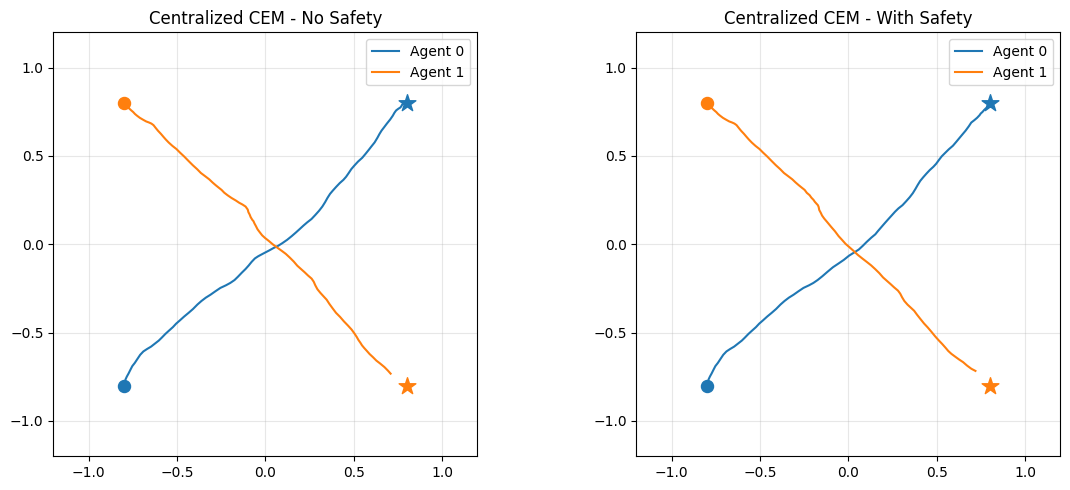

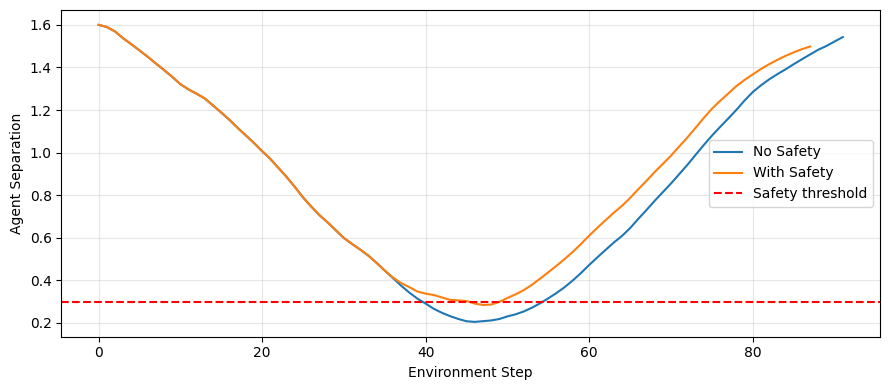

In [7]:
#Cell 7：可视化两组轨迹与安全间隔
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

colors = ["tab:blue", "tab:orange"]

for ax, trajectories, title in [
    (axes[0], traj_no, "Centralized CEM - No Safety"),
    (axes[1], traj_safe, "Centralized CEM - With Safety")
]:
    for i, tr in enumerate(trajectories):
        ax.plot(tr[:,0], tr[:,1],
                color=colors[i], label=f"Agent {i}")
        ax.scatter(*STARTS[i], color=colors[i], s=75)
        ax.scatter(*GOALS[i], color=colors[i],
                   marker="*", s=160)

    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.legend()
    ax.set_title(title)

plt.tight_layout()
plt.savefig(
    CEM_DIR / "E4B_trajectory_comparison.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(sep_no, label="No Safety")
ax.plot(sep_safe, label="With Safety")
ax.axhline(
    SAFE_DISTANCE, color="red",
    linestyle="--", label="Safety threshold"
)
ax.set_xlabel("Environment Step")
ax.set_ylabel("Agent Separation")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig(
    CEM_DIR / "E4B_separation_comparison.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

In [8]:
#Cell 8：保存 E4-B 实验结果
with open(CEM_DIR / "E4B_results.json", "w") as f:
    json.dump({
        "no_safety": result_no,
        "with_safety": result_safe
    }, f, indent=2)

np.savez_compressed(
    CEM_DIR / "E4B_trajectories.npz",
    no_safety_agent0=traj_no[0],
    no_safety_agent1=traj_no[1],
    with_safety_agent0=traj_safe[0],
    with_safety_agent1=traj_safe[1],
    no_safety_separation=sep_no,
    with_safety_separation=sep_safe
)

with open(CEM_DIR / "E4B_config.json", "w") as f:
    json.dump(CEM_CONFIG, f, indent=2)

print("E4-B results saved to:", CEM_DIR)

E4-B results saved to: /content/drive/MyDrive/MAWM_Research/E4/CEM_baselines


In [9]:
#Step 9：计算安全间隔违规的严重程度
import numpy as np
import json

def safety_statistics(separations, threshold=0.30):
    distances = np.asarray(separations)
    violations = distances < threshold

    return {
        "minimum_separation": float(distances.min()),
        "violation_steps": int(violations.sum()),
        "violation_fraction": float(violations.mean()),
        "max_violation_depth": float(
            np.maximum(threshold - distances, 0).max()
        ),
        "cumulative_violation": float(
            np.maximum(threshold - distances, 0).sum()
        )
    }

report = {
    "no_safety": safety_statistics(sep_no),
    "with_safety": safety_statistics(sep_safe)
}

print(json.dumps(report, indent=2))

with open(CEM_DIR / "E4B_safety_diagnostics.json", "w") as f:
    json.dump(report, f, indent=2)

{
  "no_safety": {
    "minimum_separation": 0.20472180843353271,
    "violation_steps": 15,
    "violation_fraction": 0.16304347826086957,
    "max_violation_depth": 0.09527819156646727,
    "cumulative_violation": 0.9090276062488554
  },
  "with_safety": {
    "minimum_separation": 0.2840611934661865,
    "violation_steps": 4,
    "violation_fraction": 0.045454545454545456,
    "max_violation_depth": 0.015938806533813465,
    "cumulative_violation": 0.04079578518867488
  }
}


In [10]:
#新建 Cell：执行多个随机种子
# ===== Step 10: Multi-Seed Evaluation =====

import pandas as pd
import numpy as np

SEEDS = [42, 43, 44]
records = []

for seed in SEEDS:
    for with_safety in [False, True]:

        result, traj, sep = run_centralized_experiment(
            with_safety=with_safety,
            seed=seed
        )

        violation = np.maximum(
            SAFE_DISTANCE - sep, 0
        )

        records.append({
            "seed": seed,
            "with_safety": with_safety,
            "joint_success": result["joint_success"],
            "steps": result["steps"],
            "minimum_separation": result["minimum_separation"],
            "violation_steps": int(
                (sep < SAFE_DISTANCE).sum()
            ),
            "cumulative_violation": float(
                violation.sum()
            ),
            "mean_planning_ms": result["mean_planning_ms"]
        })

        print(
            f"Seed={seed} | "
            f"Safety={with_safety} | "
            f"Success={result['joint_success']} | "
            f"MinSep={result['minimum_separation']:.4f}"
        )

df = pd.DataFrame(records)

display(df)

df.to_csv(
    CEM_DIR / "E4B_multi_seed_results.csv",
    index=False
)

Seed=42 | Safety=False | Success=True | MinSep=0.2047


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Seed=42 | Safety=True | Success=True | MinSep=0.2841
Seed=43 | Safety=False | Success=True | MinSep=0.1934
Seed=43 | Safety=True | Success=True | MinSep=0.3073
Seed=44 | Safety=False | Success=True | MinSep=0.2279
Seed=44 | Safety=True | Success=True | MinSep=0.3017


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,seed,with_safety,joint_success,steps,minimum_separation,violation_steps,cumulative_violation,mean_planning_ms
0,42,False,True,91,0.204722,15,0.909028,159.898684
1,42,True,True,87,0.284061,4,0.040796,155.133956
2,43,False,True,93,0.193441,13,0.824176,157.002394
3,43,True,True,93,0.307279,0,0.000000,156.560895
4,44,False,True,91,0.227926,11,0.525538,159.361038
5,44,True,True,91,0.301699,0,0.000000,162.845492


In [11]:
#新建 Cell：汇总结果
# ===== Multi-Seed Summary =====

summary = df.groupby("with_safety").agg(
    success_rate=("joint_success", "mean"),
    mean_steps=("steps", "mean"),
    mean_min_separation=("minimum_separation", "mean"),
    std_min_separation=("minimum_separation", "std"),
    mean_violation_steps=("violation_steps", "mean"),
    mean_cumulative_violation=("cumulative_violation", "mean"),
    mean_planning_ms=("mean_planning_ms", "mean")
)

display(summary)

summary.to_csv(
    CEM_DIR / "E4B_multi_seed_summary.csv"
)

print("Multi-seed evaluation saved!")

,success_rate,mean_steps,mean_min_separation,std_min_separation,mean_violation_steps,mean_cumulative_violation,mean_planning_ms
with_safety,,,,,,,
False,1.0,91.666667,0.208696,0.017583,13.000000,0.752914,158.754039
True,1.0,90.333333,0.297680,0.012120,1.333333,0.013599,158.180114


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Multi-seed evaluation saved!


In [12]:
# ===== Step 11: Multi-Scenario Evaluation =====

import pandas as pd
import numpy as np

SCENARIOS = {
    "S1_symmetric": {
        "starts": [[-0.8, -0.8], [-0.8, 0.8]],
        "goals":  [[0.8, 0.8], [0.8, -0.8]]
    },
    "S2_perpendicular": {
        "starts": [[-0.8, 0.0], [0.2, 0.8]],
        "goals":  [[0.8, 0.0], [0.2, -0.8]]
    },
    "S3_asymmetric": {
        "starts": [[-0.8, 0.5], [-0.8, -0.8]],
        "goals":  [[0.8, -0.5], [0.8, 0.7]]
    }
}

original_starts = STARTS.copy()
original_goals = GOALS.copy()

records = []

try:
    for name, scene in SCENARIOS.items():

        STARTS = np.array(scene["starts"], dtype=np.float32)
        GOALS = np.array(scene["goals"], dtype=np.float32)

        for seed in [42, 43, 44]:
            for with_safety in [False, True]:

                result, traj, sep = run_centralized_experiment(
                    with_safety=with_safety,
                    seed=seed
                )

                violation = np.maximum(
                    SAFE_DISTANCE - sep, 0
                )

                records.append({
                    "scenario": name,
                    "seed": seed,
                    "with_safety": with_safety,
                    "joint_success": result["joint_success"],
                    "steps": result["steps"],
                    "min_separation": result["minimum_separation"],
                    "violation_steps": int(
                        (sep < SAFE_DISTANCE).sum()
                    ),
                    "cumulative_violation": float(
                        violation.sum()
                    ),
                    "mean_planning_ms": result["mean_planning_ms"]
                })

                print(
                    f"{name} | seed={seed} | "
                    f"safety={with_safety} | "
                    f"success={result['joint_success']} | "
                    f"min_sep={result['minimum_separation']:.4f}"
                )
finally:
    # 恢复原来的 S1 场景，避免影响后续实验
    STARTS = original_starts
    GOALS = original_goals

multi_df = pd.DataFrame(records)
display(multi_df)

multi_df.to_csv(
    CEM_DIR / "E4B_multi_scenario_results.csv",
    index=False
)

print("Multi-scenario results saved!")

S1_symmetric | seed=42 | safety=False | success=True | min_sep=0.2047
S1_symmetric | seed=42 | safety=True | success=True | min_sep=0.2841
S1_symmetric | seed=43 | safety=False | success=True | min_sep=0.1934
S1_symmetric | seed=43 | safety=True | success=True | min_sep=0.3073
S1_symmetric | seed=44 | safety=False | success=True | min_sep=0.2279
S1_symmetric | seed=44 | safety=True | success=True | min_sep=0.3017
S2_perpendicular | seed=42 | safety=False | success=True | min_sep=0.1955
S2_perpendicular | seed=42 | safety=True | success=True | min_sep=0.2949
S2_perpendicular | seed=43 | safety=False | success=True | min_sep=0.1994
S2_perpendicular | seed=43 | safety=True | success=True | min_sep=0.2911
S2_perpendicular | seed=44 | safety=False | success=True | min_sep=0.2093
S2_perpendicular | seed=44 | safety=True | success=True | min_sep=0.2988
S3_asymmetric | seed=42 | safety=False | success=True | min_sep=0.1948
S3_asymmetric | seed=42 | safety=True | success=True | min_sep=0.2883
S

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,scenario,seed,with_safety,joint_success,steps,min_separation,violation_steps,cumulative_violation,mean_planning_ms
0,S1_symmetric,42,False,True,91,0.204722,15,0.909028,159.711958
1,S1_symmetric,42,True,True,87,0.284061,4,0.040796,157.021011
2,S1_symmetric,43,False,True,93,0.193441,13,0.824176,158.807971
3,S1_symmetric,43,True,True,93,0.307279,0,0.000000,157.643916
4,S1_symmetric,44,False,True,91,0.227926,11,0.525538,157.132520
5,S1_symmetric,44,True,True,91,0.301699,0,0.000000,158.057439
6,S2_perpendicular,42,False,True,67,0.195461,15,0.984757,160.883632
7,S2_perpendicular,42,True,True,71,0.294894,5,0.016489,156.926783
8,S2_perpendicular,43,False,True,69,0.199415,16,0.967373,159.770699
9,S2_perpendicular,43,True,True,69,0.291077,6,0.022931,153.635406


Multi-scenario results saved!


In [13]:
#保存多场景汇总
summary = multi_df.groupby(
    ["scenario", "with_safety"]
).agg(
    success_rate=("joint_success", "mean"),
    mean_steps=("steps", "mean"),
    mean_min_separation=("min_separation", "mean"),
    mean_violation_steps=("violation_steps", "mean"),
    mean_cumulative_violation=("cumulative_violation", "mean"),
    mean_planning_ms=("mean_planning_ms", "mean")
).reset_index()

display(summary)

summary.to_csv(
    CEM_DIR / "E4B_multi_scenario_summary.csv",
    index=False
)

,scenario,with_safety,success_rate,mean_steps,mean_min_separation,mean_violation_steps,mean_cumulative_violation,mean_planning_ms
0,S1_symmetric,False,1.0,91.666667,0.208696,13.000000,0.752914,158.550816
1,S1_symmetric,True,1.0,90.333333,0.297680,1.333333,0.013599,157.574122
2,S2_perpendicular,False,1.0,69.333333,0.201392,18.333333,1.205165,160.727098
3,S2_perpendicular,True,1.0,70.666667,0.294935,4.000000,0.013529,156.822226
4,S3_asymmetric,False,1.0,81.000000,0.194943,24.000000,1.815505,164.074684
5,S3_asymmetric,True,1.0,86.666667,0.293280,4.333333,0.032588,155.155828


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [14]:
# ===== Old CEM First-Action Audit =====

audit_env = create_scenario(1)
audit_sim = create_scenario(CEM_CONFIG["population"])

old_positions = np.stack([
    a.state.pos[0].detach().cpu().numpy()
    for a in audit_env.agents
])

old_velocities = np.stack([
    a.state.vel[0].detach().cpu().numpy()
    for a in audit_env.agents
])

old_action, old_info = centralized_cem(
    audit_sim,
    old_positions,
    old_velocities,
    CEM_CONFIG,
    with_safety=True,
    seed=42
)

print("OLD action:")
print(old_action.detach().cpu().numpy())

print("OLD best cost:", old_info["best_cost"])

OLD action:
[[ 0.49458385  0.6152454 ]
 [ 0.5867461  -0.7140306 ]]
OLD best cost: 21.403921127319336
